# 6주차 · 고객 리뷰 데이터의 가공 및 분석 — 완성본

**인공지능과 데이터 활용** · 네이버 쇼핑 **실제 상품 후기 300건**으로
사람이 만든 **키워드 규칙**과 **AI(머신러닝) 감성분석**을 직접 만들어 보고, 두 결과를 비교·검증합니다.

| 워크북 | 하는 일 | 핵심 코드 | 산출물 |
|---|---|---|---|
| 1. 불러오기·정제·탐색 | 품질 점검, 텍스트 정리, 길이·단어 빈도 | `read_csv` `isna` `str.replace` `Counter` | 그림 2장 |
| 2. 수작업 키워드 분류 | 직접 읽고 라벨링 → 키워드 규칙 v1 → 개선 v2·v3 | `def` 함수 `apply` `value_counts` | 규칙 비교표 |
| 3. AI 감성분석 | 19만 9천 건으로 학습 → 300건 예측, AI가 본 단서 확인 | `TfidfVectorizer` `LogisticRegression` | 예측표, 그림 2장 |
| 4. 비교·평가 | 교차표, 일치율, 별점 대비 정확도, 불일치 사례 | `crosstab` `classification_report` | `week06_results.csv` |

**실행:** `런타임 → 모두 실행` (약 1~2분). 실습본은 `TODO`의 `...`을 채운 뒤 실행하고 **기대값**과 비교합니다.
API 키·유료 서비스는 필요 없습니다.

> 데이터: bab2min/corpus 네이버쇼핑 후기(2020, Public Domain)에서 워크북 0 규칙으로 뽑은 300건.
> `rating_label`(별점 4~5=긍정, 1~2=부정)은 **참고 라벨**이지 정답이 아닙니다.

## 0. 실행 환경 준비

In [1]:
!pip -q install koreanize-matplotlib      # 그래프 한글 표시 (처음 한 번, 약 10초)

In [2]:
import os, re, time
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")   # 버전 차이로 나오는 경고 숨김
import koreanize_matplotlib              # import만 하면 그래프 한글이 깨지지 않음
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("figures", exist_ok=True)

### 데이터 위치 선택 (`DATA_SOURCE`)
| 값 | 동작 | 쓰는 상황 |
|---|---|---|
| `"auto"` (기본) | GitHub 수업 저장소에서 읽고, 안 되면 **내 Google Drive**에서 `week06_MANIFEST.csv`가 있는 폴더를 자동으로 찾음 | 평소 |
| `"drive"` | 내 Drive에 미리 저장한 데이터만 사용 (처음 한 번 Drive 접근 허용) | 수업 중 GitHub가 불안정할 때 |
| `"upload"` | 내려받아 둔 파일을 직접 업로드 | Drive 연결이 어려울 때 |

어느 경로든 노트북이 파일마다 **MD5(파일 지문)** 를 확인해 `정상` 여부를 표로 보여 줍니다. 같은 파일이면 기대값도 똑같이 나옵니다.

In [3]:
# ── 데이터 위치 선택 ─────────────────────────────────────────
DATA_SOURCE = "auto"          # "auto" | "drive" | "upload" | "github"

import os, glob, io, gzip, hashlib, urllib.request
import pandas as pd

GITHUB_BASE = "https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week06/data/"
MANIFEST = "week06_MANIFEST.csv"

def _find_in_drive():
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    for depth in range(0, 7):                                   # 내 드라이브 아래 6단계까지 탐색
        hits = sorted(glob.glob("/content/drive/MyDrive/" + "*/" * depth + MANIFEST))
        if hits:
            return os.path.dirname(hits[0]) + "/"
    raise FileNotFoundError("내 Drive에서 week06_MANIFEST.csv 를 찾지 못했습니다.\n"
        "· 공유받은 '강의6주/01_데이터' 폴더를 오른쪽 클릭 → 정리 → '바로가기 추가' → '내 드라이브' 후 다시 실행하세요.")

def _upload():
    from google.colab import files
    os.makedirs("week06_data", exist_ok=True)
    print("01_데이터 폴더에서 내려받은 파일(week06_MANIFEST.csv 포함)을 모두 선택하세요.")
    for name, data in files.upload().items():
        open(os.path.join("week06_data", name), "wb").write(data)
    return "week06_data/"

def resolve_base(source=DATA_SOURCE):
    if source in ("auto", "github"):
        try:
            urllib.request.urlopen(GITHUB_BASE + MANIFEST, timeout=15).read()
            return GITHUB_BASE
        except Exception as e:
            if source == "github":
                raise
            print("GitHub 접속 실패 → Google Drive에서 찾습니다:", type(e).__name__)
            source = "drive"
    if source == "drive":
        return _find_in_drive()
    if source == "upload":
        return _upload()
    if os.path.isdir(source):                                   # 폴더 경로를 직접 적은 경우
        return source.rstrip("/") + "/"
    raise ValueError("DATA_SOURCE 값을 확인하세요: " + str(source))

def read_bytes(name):
    if BASE.startswith("http"):
        return urllib.request.urlopen(BASE + name, timeout=120).read()
    return open(BASE + name, "rb").read()

BASE = resolve_base()
manifest = pd.read_csv(io.BytesIO(read_bytes(MANIFEST)), encoding="utf-8-sig")
print("데이터 위치:", BASE)
manifest[["file", "bytes", "rows", "note"]]

데이터 위치: https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week06/data/


,file,bytes,rows,note
0,week06_reviews_300.csv,36901,300,수업용 표본 (워크북 1~4 입력)
1,naver_shopping.txt.gz,7699143,200000,"원자료 미러, 압축 해제 MD5=cd029e474cd8724af42244cc1207..."


In [4]:
# 파일 지문(MD5) 확인: 수업 저장소 원본과 똑같은 파일인지 검사
def check_file(name):
    data = read_bytes(name)
    expected = manifest.set_index("file").loc[name, "md5"]
    ok = hashlib.md5(data).hexdigest() == expected
    print(f"{name:28s} {len(data):>10,} bytes  →  {'정상(MD5 일치)' if ok else '⚠ 다른 파일! 강의자에게 알리세요'}")
    return data

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

---
# 워크북 1 · 리뷰 불러오기 · 정제 · 탐색
```
불러오기 → 구조 확인 → 품질 점검(결측·중복) → 텍스트 정리(원문 보존) → 길이·별점·단어 빈도 탐색
```
### 1-1. 불러오기

In [5]:
# TODO 1: 수업 데이터를 읽으세요.  힌트: pd.read_csv(io.BytesIO(data), encoding="utf-8-sig")
data = check_file("week06_reviews_300.csv")
df = pd.read_csv(io.BytesIO(data), encoding="utf-8-sig")
print("행, 열:", df.shape)
df.head()

week06_reviews_300.csv           36,901 bytes  →  정상(MD5 일치)
행, 열: (300, 5)


,review_id,src_line,rating,rating_label,review_text
0,R001,192873,4,긍정,오리상태도 좋고 밋도 있어여 다만 포장에 기름이 좀 묻어 있어서 별하나 뺐어요
1,R002,81447,4,긍정,세팅력이 우수합니다
2,R003,94168,5,긍정,"화장하기 편하고, 피부표현이 매끄럽게 되용"
3,R004,72762,2,부정,뚜껑끼우는게 너무 힘들어서 손이 많이 아픕니다. 통이 찌그러져오지않았다면 그렇게 힘들진않을텐데 10개중 서너개는 심하게 찌그러져오네요. ...
4,R005,26587,2,부정,일단 패드장착이 안되어 왔구요~ 패드부분만 볼록하게 튀어나와서 너무 티가나요~


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   review_id     300 non-null    object
 1   src_line      300 non-null    int64 
 2   rating        300 non-null    int64 
 3   rating_label  300 non-null    object
 4   review_text   300 non-null    object
dtypes: int64(2), object(3)
memory usage: 11.8+ KB


**기대값:** `(300, 5)` · 열 `review_id, src_line, rating, rating_label, review_text` · 첫 행 `R001 … 오리상태도 좋고 밋도 있어여 …`

### 1-2. 품질 점검 — 결측·중복·라벨 분포

In [7]:
check = pd.Series({
    "review_text 결측": df["review_text"].isna().sum(),
    "review_id 중복": df["review_id"].duplicated().sum(),
    "같은 문장 중복": df["review_text"].duplicated().sum(),
    "빈 문자열": (df["review_text"].str.strip() == "").sum(),
}, name="건수")
display(check.to_frame())
display(pd.crosstab(df["rating"], df["rating_label"], margins=True, margins_name="합계"))

,건수
review_text 결측,0
review_id 중복,0
같은 문장 중복,0
빈 문자열,0


rating_label,긍정,부정,합계
rating,,,
1,0,75,75
2,0,75,75
4,75,0,75
5,75,0,75
합계,150,150,300


**기대값:** 결측·중복·빈 문자열 모두 0 · 별점 1·2·4·5 각 75건 · 긍정 150 / 부정 150

### 1-3. 텍스트 정리 — 원문은 남기고 분석용 열을 새로 만든다
| 규칙 | 예 | 이유 |
|---|---|---|
| 앞뒤 공백 제거, 연속 공백 1칸 | `"좋아요  !"` → `"좋아요 !"` | 띄어쓰기 차이 줄이기 |
| 같은 기호·자모 3번 이상 반복 → 2번 | `"ㅠㅠㅠㅠ"`→`"ㅠㅠ"`, `"~~~~~"`→`"~~"` | 표기 차이 줄이기 |

맞춤법을 고치거나 단어를 지우지는 않습니다. **의미가 바뀌는 가공은 하지 않는다**가 원칙입니다.

In [8]:
def clean_text(t):
    t = str(t).strip()
    t = re.sub(r"\s+", " ", t)                         # 연속 공백 → 1칸
    # TODO 2: 같은 문자가 3번 이상 반복되면 2번으로 줄이세요.  힌트: re.sub(r"(.)\1{2,}", r"\1\1", t)
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)
    return t

df["text"] = df["review_text"].map(clean_text)
df["length"] = df["text"].str.len()
changed = df[df["text"] != df["review_text"]]
print("정리로 바뀐 후기:", len(changed), "건")
changed[["review_id", "review_text", "text"]].head(6)

정리로 바뀐 후기: 45 건


,review_id,review_text,text
7,R008,대구지역~~~~아직 제품과 만나지 못했네요 친절하게도 집안에 배송을 해주셔서~~~~~,대구지역~~아직 제품과 만나지 못했네요 친절하게도 집안에 배송을 해주셔서~~
14,R015,부서져서왔어요... 상자를 버려서 교환못한고 걍 써요 ㅠㅠ,부서져서왔어요.. 상자를 버려서 교환못한고 걍 써요 ㅠㅠ
26,R027,테이블상판이 늘려써야한다는 고지를못보고 교환요청해 물건을 보냈다가 다시그대로 받는바람에 배송비를 낸것까지는 나쁘지않은데.. 배송되어온 제...,테이블상판이 늘려써야한다는 고지를못보고 교환요청해 물건을 보냈다가 다시그대로 받는바람에 배송비를 낸것까지는 나쁘지않은데.. 배송되어온 제...
28,R029,"아....뿌리다 보니까...,유광 흰색을 주문했는데....유광 클리어가 왔네요...아...........신경좀 써서 배송해주세요........","아..뿌리다 보니까..,유광 흰색을 주문했는데..유광 클리어가 왔네요..아..신경좀 써서 배송해주세요.."
41,R042,빠른배송과 빠짐없는 구성에 참 좋네요 ㅎㅎㅎ 밤이 기대되네요 ㅎㅎㅎ,빠른배송과 빠짐없는 구성에 참 좋네요 ㅎㅎ 밤이 기대되네요 ㅎㅎ
42,R043,논슬립부분이 스티커더라고요 한달쓰니깐 그논슬립부분들이 떨어져나갑니다 후....,논슬립부분이 스티커더라고요 한달쓰니깐 그논슬립부분들이 떨어져나갑니다 후..


### 1-4. 탐색 — 별점과 길이

              count  mean   std   min   25%   50%   75%    max
rating_label                                                  
긍정            150.0  33.8  23.4  10.0  17.0  26.0  43.0  122.0
부정            150.0  45.7  32.9   9.0  19.0  35.5  63.5  138.0


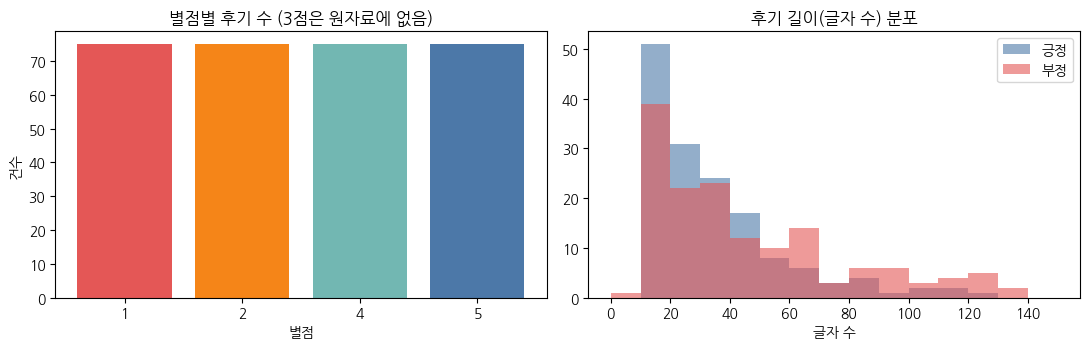

In [9]:
print(df.groupby("rating_label")["length"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cnt = df["rating"].value_counts().sort_index()
axes[0].bar(cnt.index.astype(str), cnt.values, color=["#E45756", "#F58518", "#72B7B2", "#4C78A8"])
axes[0].set_title("별점별 후기 수 (3점은 원자료에 없음)"); axes[0].set_xlabel("별점"); axes[0].set_ylabel("건수")
for lab, col in [("긍정", "#4C78A8"), ("부정", "#E45756")]:
    axes[1].hist(df.loc[df["rating_label"] == lab, "length"], bins=range(0, 160, 10), alpha=.6, label=lab, color=col)
axes[1].set_title("후기 길이(글자 수) 분포"); axes[1].set_xlabel("글자 수"); axes[1].legend()
plt.tight_layout(); plt.savefig("figures/fig_w1_rating_length.png", dpi=120); plt.show()

**기대값:** 정리로 바뀐 후기 45건 · 긍정 평균 **33.8자**, 부정 평균 **45.7자** → **불만 후기가 더 길다**. 왜 그럴지 생각해 보세요.

### 1-5. 어떤 단어가 많이 나오나? — 어절(띄어쓰기 단위) 빈도

In [10]:
def tokens(t):
    return re.findall(r"[가-힣A-Za-z0-9]+", t)          # 한글·영문·숫자 덩어리만

# TODO 3: 긍정·부정 후기 각각에서 가장 많이 나온 어절 15개를 세세요.  힌트: Counter(...).most_common(15)
top = {}
for lab in ["긍정", "부정"]:
    words = [w for t in df.loc[df["rating_label"] == lab, "text"] for w in tokens(t)]
    top[lab] = Counter(words).most_common(15)
display(pd.DataFrame({lab: [f"{w} ({n})" for w, n in top[lab]] for lab in top}))

,긍정,부정
0,좋아요 (19),그냥 (17)
1,재구매 (18),너무 (16)
2,잘 (18),좀 (15)
3,너무 (9),잘 (9)
4,좀 (8),많이 (8)
5,일단 (7),샀는데 (6)
6,아주 (7),없고 (5)
7,같아요 (7),작아서 (5)
8,더 (7),재구매 (5)
9,많이 (6),생각보다 (5)


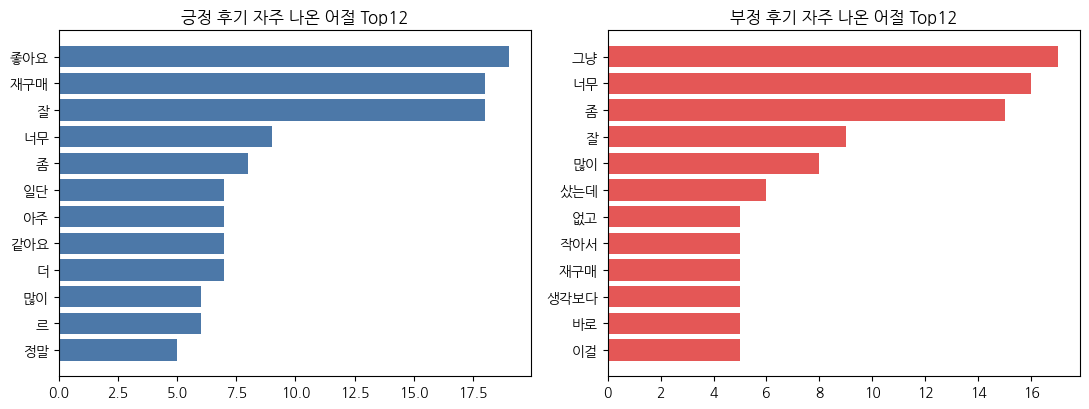

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (lab, col) in zip(axes, [("긍정", "#4C78A8"), ("부정", "#E45756")]):
    w, n = zip(*top[lab][:12])
    ax.barh(w[::-1], n[::-1], color=col); ax.set_title(f"{lab} 후기 자주 나온 어절 Top12")
plt.tight_layout(); plt.savefig("figures/fig_w1_top_words.png", dpi=120); plt.show()

**관찰:** `좋아요`, `좋고`, `좋은`은 같은 뜻인데 다른 어절로 세어집니다(한국어는 조사·어미가 붙음).
→ 워크북 2에서는 단어 전체가 아니라 **`좋`, `만족`처럼 앞부분(부분 문자열)** 으로 찾는 이유가 됩니다.
`너무`, `잘`, `안`은 긍정·부정 양쪽에 다 나옵니다 — 단어 하나만으로는 감성을 정하기 어렵습니다.

---
# 워크북 2 · 수작업 키워드 분류
```
사람이 직접 10건 읽고 판단 → 판단 근거가 된 단어를 목록으로 → 규칙 함수 v1 → 틀린 사례 분석 → 규칙 개선 v2 → 내 단어 추가 v3
```
### 2-1. 먼저 사람이 읽고 판단하기 (R001~R010)
아래 10건을 읽고 `MY_LABELS`에 **긍정/부정/중립**을 적으세요. 별점(`rating`)은 보지 말고 **문장만** 보고 판단합니다.
결과는 Drive `03_워크북`의 **워크북 기록지(Google Sheets)** 에도 적습니다.

In [12]:
for _, r in df.head(10).iterrows():
    print(r["review_id"], "|", r["text"])

R001 | 오리상태도 좋고 밋도 있어여 다만 포장에 기름이 좀 묻어 있어서 별하나 뺐어요
R002 | 세팅력이 우수합니다
R003 | 화장하기 편하고, 피부표현이 매끄럽게 되용
R004 | 뚜껑끼우는게 너무 힘들어서 손이 많이 아픕니다. 통이 찌그러져오지않았다면 그렇게 힘들진않을텐데 10개중 서너개는 심하게 찌그러져오네요. 두꺼우니 손으로 잘 펴지지도 않구요ㅠ
R005 | 일단 패드장착이 안되어 왔구요~ 패드부분만 볼록하게 튀어나와서 너무 티가나요~
R006 | 일단 강추 입니다 세련 되었고 싼티 나지 않습니다 만족스럽스니다
R007 | 잘받았어요. 잘쓸깨요
R008 | 대구지역~~아직 제품과 만나지 못했네요 친절하게도 집안에 배송을 해주셔서~~
R009 | 사료 두번째 구입인데 넘잘먹네요 계량컵두 주시고 배송도빠르고 적극 추천합니다
R010 | 맛있었어요 2명 먹는데 양도적당했는데 당면양이 아주많네요


In [13]:
# TODO 4: 내가 읽고 판단한 감성을 적으세요 ("긍정" / "부정" / "중립")
MY_LABELS = {"R001": "긍정", "R002": "긍정", "R003": "긍정", "R004": "부정", "R005": "부정",
             "R006": "긍정", "R007": "긍정", "R008": "긍정", "R009": "긍정", "R010": "긍정"}

human = df.head(10)[["review_id", "rating", "rating_label", "text"]].copy()
human["my_label"] = human["review_id"].map(MY_LABELS)
human["별점과 같나"] = np.where(human["my_label"] == human["rating_label"], "O", "X")
display(human)
print("내 판단과 별점 라벨 일치:", (human["별점과 같나"] == "O").sum(), "/ 10")

,review_id,rating,rating_label,text,my_label,별점과 같나
0,R001,4,긍정,오리상태도 좋고 밋도 있어여 다만 포장에 기름이 좀 묻어 있어서 별하나 뺐어요,긍정,O
1,R002,4,긍정,세팅력이 우수합니다,긍정,O
2,R003,5,긍정,"화장하기 편하고, 피부표현이 매끄럽게 되용",긍정,O
3,R004,2,부정,뚜껑끼우는게 너무 힘들어서 손이 많이 아픕니다. 통이 찌그러져오지않았다면 그렇게 힘들진않을텐데 10개중 서너개는 심하게 찌그러져오네요. ...,부정,O
4,R005,2,부정,일단 패드장착이 안되어 왔구요~ 패드부분만 볼록하게 튀어나와서 너무 티가나요~,부정,O
5,R006,5,긍정,일단 강추 입니다 세련 되었고 싼티 나지 않습니다 만족스럽스니다,긍정,O
6,R007,5,긍정,잘받았어요. 잘쓸깨요,긍정,O
7,R008,5,긍정,대구지역~~아직 제품과 만나지 못했네요 친절하게도 집안에 배송을 해주셔서~~,긍정,O
8,R009,2,부정,사료 두번째 구입인데 넘잘먹네요 계량컵두 주시고 배송도빠르고 적극 추천합니다,긍정,X
9,R010,4,긍정,맛있었어요 2명 먹는데 양도적당했는데 당면양이 아주많네요,긍정,O


내 판단과 별점 라벨 일치: 9 / 10


**강의자 판단 기준값:** 10건 중 9건 일치. **R009**(별점 2점)는 *"넘잘먹네요 … 배송도빠르고 적극 추천합니다"* — 문장은 긍정인데 별점은 부정.
→ 별점 라벨에도 **잡음(noise)** 이 있습니다. 내가 판단할 때 근거가 된 단어(좋고, 우수, 편하고, 찌그러져 …)에 밑줄을 쳐 보세요.

### 2-2. 키워드 규칙 v1 — 단어 8개씩
**규칙:** 긍정 단어 수(p)와 부정 단어 수(n)를 센다 → `p > n` 긍정, `n > p` 부정, 같으면(0:0 포함) **중립(판단 보류)**

In [14]:
POS_V1 = ["좋아", "좋고", "만족", "추천", "최고", "맛있", "예뻐", "빠르"]
NEG_V1 = ["별로", "실망", "불량", "고장", "반품", "냄새", "불편", "최악"]

# TODO 5: 문장에 들어 있는 긍정·부정 단어 수를 세서 라벨을 돌려주는 함수를 완성하세요.
def rule_v1(text):
    p = sum(w in text for w in POS_V1)
    n = sum(w in text for w in NEG_V1)
    return "긍정" if p > n else ("부정" if n > p else "중립")

print(rule_v1("배송 빠르고 좋아요"), rule_v1("냄새가 너무 나요"), rule_v1("그냥 그래요"))
df["rule_v1"] = df["text"].map(rule_v1)
df["rule_v1"].value_counts()

긍정 부정 중립


rule_v1
중립    199
긍정     67
부정     34
Name: count, dtype: int64

In [15]:
def rule_score(col):
    decided = df[df[col] != "중립"]
    return pd.Series({"판정 비율(중립 제외)": len(decided) / len(df),
                      "판정한 것 중 별점 일치": (decided[col] == decided["rating_label"]).mean(),
                      "전체 300건 기준 일치": (df[col] == df["rating_label"]).mean()}).round(3)
rule_score("rule_v1")

판정 비율(중립 제외)     0.337
판정한 것 중 별점 일치    0.842
전체 300건 기준 일치    0.283
dtype: float64

**기대값:** v1 → 긍정 67 · 부정 34 · 중립 **199** · 판정 비율 **0.337** · 판정한 것 중 일치 **0.842** · 전체 기준 **0.283**

**해석:** 판단한 것은 꽤 맞지만, **3건 중 2건은 단어를 못 찾아(또는 동점이라) 판단을 못 했습니다.**

### 2-3. v1이 놓치거나 틀리는 문장

In [16]:
def show(mask, title, n=6):
    print(f"▶ {title}: {mask.sum()}건")
    display(df.loc[mask, ["review_id", "rating_label", "rule_v1", "text"]].head(n))

show(df["rule_v1"].eq("중립"), "단어를 하나도 못 찾음(중립)")
show(df["text"].str.contains(r"안 ?좋|좋지 ?않|안 ?맞|안 ?되|못하"), "부정어(안·못·않)가 붙은 문장")
show(df["text"].str.contains(r"지만|는데|다만|그런데"), "앞뒤가 다른 말(지만·는데·다만)")
show((df["rule_v1"] != "중립") & (df["rule_v1"] != df["rating_label"]), "판정했지만 별점과 다름")

▶ 단어를 하나도 못 찾음(중립): 199건


,review_id,rating_label,rule_v1,text
1,R002,긍정,중립,세팅력이 우수합니다
2,R003,긍정,중립,"화장하기 편하고, 피부표현이 매끄럽게 되용"
3,R004,부정,중립,뚜껑끼우는게 너무 힘들어서 손이 많이 아픕니다. 통이 찌그러져오지않았다면 그렇게 힘들진않을텐데 10개중 서너개는 심하게 찌그러져오네요. ...
4,R005,부정,중립,일단 패드장착이 안되어 왔구요~ 패드부분만 볼록하게 튀어나와서 너무 티가나요~
6,R007,긍정,중립,잘받았어요. 잘쓸깨요
7,R008,긍정,중립,대구지역~~아직 제품과 만나지 못했네요 친절하게도 집안에 배송을 해주셔서~~


▶ 부정어(안·못·않)가 붙은 문장: 26건


,review_id,rating_label,rule_v1,text
4,R005,부정,중립,일단 패드장착이 안되어 왔구요~ 패드부분만 볼록하게 튀어나와서 너무 티가나요~
15,R016,긍정,긍정,정말 맛있게 잘먹었습니다. 다만 내장손잘이 안되어있어 직접 손질하는게 귀찮..
17,R018,긍정,중립,재구매 무료배송 건이랑 같이 구매해서 무료배송안되냐고 했더니 따로 보내야 한다고 하셔서 배송비 내고 받았어요. 그런데 배송은 다 합쳐서 ...
51,R052,부정,중립,2XL와3XL 한싸이차이가 너무 많이나요 2XL은 작아서 후크 잠그기가 힘들고 3XL는 너무크서 압박이 안되네요
68,R069,부정,부정,비커컵은 생각보다 크구여 컵이 불량이라 교체하는데 여러모로 힘들엇네요 톡톡응대가 만족스럽지않아 바로 응대가 안되드라구요 결국 상담전화까지...
80,R081,부정,긍정,유통기한이 너무짧아요~ 도착일기준로 15일도 안되네요~ 아이들 간식용으로 많이 샀는데 다 버릴거같네요. 한번에 많이 드실거 아님 추천하지...


▶ 앞뒤가 다른 말(지만·는데·다만): 88건


,review_id,rating_label,rule_v1,text
0,R001,긍정,긍정,오리상태도 좋고 밋도 있어여 다만 포장에 기름이 좀 묻어 있어서 별하나 뺐어요
9,R010,긍정,긍정,맛있었어요 2명 먹는데 양도적당했는데 당면양이 아주많네요
11,R012,부정,부정,"일본 대체품으로 구매를 했으나 실망을 많이 했습니다. 쿨링효과도 없고, 발닥에 덕지덕지 붙어서 떼어내는데 짜증납니다! 애국심에 샀는데~ ..."
15,R016,긍정,긍정,정말 맛있게 잘먹었습니다. 다만 내장손잘이 안되어있어 직접 손질하는게 귀찮..
16,R017,긍정,중립,효과 굿 효과 있네요. 두개샀는데 고민했음. 안될까봐 호과 아주 굿입니다. 담에는 nfc카드가 필요산데 얻서 그매하나요.
17,R018,긍정,중립,재구매 무료배송 건이랑 같이 구매해서 무료배송안되냐고 했더니 따로 보내야 한다고 하셔서 배송비 내고 받았어요. 그런데 배송은 다 합쳐서 ...


▶ 판정했지만 별점과 다름: 16건


,review_id,rating_label,rule_v1,text
8,R009,부정,긍정,사료 두번째 구입인데 넘잘먹네요 계량컵두 주시고 배송도빠르고 적극 추천합니다
34,R035,긍정,부정,마음에들어요 키높이는 별로
67,R068,부정,긍정,배송도 빠르고 포장도 잘 되어왔어요. 잘 사용할게요
80,R081,부정,긍정,유통기한이 너무짧아요~ 도착일기준로 15일도 안되네요~ 아이들 간식용으로 많이 샀는데 다 버릴거같네요. 한번에 많이 드실거 아님 추천하지...
81,R082,부정,긍정,조금 비싼거 같아요 그래도 맛있어요
84,R085,부정,긍정,배송도빠르고 원하던디자인에 차량색상이랑도 잘맞고 딱이네요


| 실패 유형 | 예 | 원인 |
|---|---|---|
| 단어 목록이 좁음 | `배송이 너어어무 느림`, `싸이즈가 좀 작네요` | `느림`, `작` 이 목록에 없음 |
| 부정어 | `접착성 완전 안좋아요`(R295) → `좋아`가 들어 있어 **긍정** | 단어가 있는지만 보고 앞의 `안`을 무시 |
| 대조(지만·다만) | `면부분이 좁고 … 그밖의 것은 만족`(R111, 별점 5) | 앞·뒤 중 무엇이 중요한지 모름 |
| 별점 잡음 | `배송도빠르고 … 딱이네요`(R085, 별점 1) | 규칙은 맞았는데 라벨이 이상 |

### 2-4. 규칙 v2 — 단어 늘리기 + 부정어 처리
- 긍정·부정 단어를 늘린다 (자주 나온 어절, 2-3의 실패 사례 참고)
- **부정 표현**(`안좋`, `좋지 않`, `재구매 의사 없` …)이 있으면 부정 점수 **+2** (긍정 단어 1개를 이기도록)

In [17]:
POS_V2 = POS_V1 + ["좋네", "좋습", "좋은", "좋았", "괜찮", "굿", "짱", "편해", "편하", "편리", "튼튼", "저렴", "감사",
                   "재구매", "잘 쓰", "잘쓰", "잘 사용", "잘먹", "잘 먹", "예쁘", "이뻐", "이쁘", "깔끔", "마음에 들",
                   "맘에 들", "마음에들", "맘에들", "훌륭", "가성비", "강추", "넉넉", "딱이", "꼼꼼", "친절", "귀여"]
NEG_V2 = NEG_V1 + ["아쉽", "아쉬", "늦", "느려", "느림", "작아", "작네", "얇", "파손", "찢어", "깨져", "엉망", "비싸",
                   "교환", "환불", "떨어져", "떨어졌", "불만", "비추", "망가", "터져", "별루", "부서", "찌그러",
                   "안 맞", "안맞", "안되", "안 되", "못하", "없어요", "없네", "딱딱", "심해", "힘들", "짜증", "그냥 그"]
NEGATION = ["안좋", "안 좋", "좋지 않", "좋지않", "만족하지 못", "만족스럽지 않", "만족스럽지않",
            "재구매 의사 없", "재구매의사없", "안 살", "안살", "다신", "다시는", "다음엔 안"]

def rule_score_parts(text, pos, neg):
    p = sum(w in text for w in pos)
    n = sum(w in text for w in neg) + 2 * sum(w in text for w in NEGATION)
    return p, n

# TODO 6: rule_score_parts를 이용해 v2 판정 함수를 완성하세요. (p > n 긍정, n > p 부정, 같으면 중립)
def rule_v2(text):
    p, n = rule_score_parts(text, POS_V2, NEG_V2)
    return "긍정" if p > n else ("부정" if n > p else "중립")

df["rule_v2"] = df["text"].map(rule_v2)
print(df["rule_v2"].value_counts().to_dict())
rule_score("rule_v2")

{'긍정': 124, '중립': 90, '부정': 86}


판정 비율(중립 제외)     0.700
판정한 것 중 별점 일치    0.881
전체 300건 기준 일치    0.617
dtype: float64

**기대값:** v2 → 긍정 124 · 부정 86 · 중립 90 · 판정 비율 **0.700** · 판정한 것 중 일치 **0.881** · 전체 기준 **0.617**

단어를 늘리고 부정어를 처리하자 판단 보류가 199건 → 90건으로 줄었습니다. R295 `안좋아요`도 이제 부정입니다.

### 2-5. 규칙 v3 — 내가 찾은 단어 추가하기
2-3에서 놓친 문장을 보고 **긍정 3개 이상, 부정 3개 이상**을 직접 추가하세요. 추가 전후로 무엇이 좋아지고 무엇이 나빠졌는지 기록합니다.

In [18]:
# TODO 7: 내가 찾은 단어를 3개 이상씩 넣으세요 (완성본은 예시)
MY_POS = ["만족스럽", "향이 좋", "맛납", "든든"]
MY_NEG = ["버리", "구겨", "엉성", "새어", "흘러"]

def rule_v3(text):
    p, n = rule_score_parts(text, POS_V2 + MY_POS, NEG_V2 + MY_NEG)
    return "긍정" if p > n else ("부정" if n > p else "중립")

df["rule_v3"] = df["text"].map(rule_v3)
compare_rules = pd.DataFrame({c: rule_score(c) for c in ["rule_v1", "rule_v2", "rule_v3"]})
display(compare_rules)
changed = df[df["rule_v3"] != df["rule_v2"]]
print("v2 → v3 에서 판정이 바뀐 후기:", len(changed), "건")
display(changed[["review_id", "rating_label", "rule_v2", "rule_v3", "text"]].head(8))

,rule_v1,rule_v2,rule_v3
판정 비율(중립 제외),0.337,0.700,0.697
판정한 것 중 별점 일치,0.842,0.881,0.885
전체 300건 기준 일치,0.283,0.617,0.617


v2 → v3 에서 판정이 바뀐 후기: 3 건


,review_id,rating_label,rule_v2,rule_v3,text
36,R037,부정,중립,부정,흘러내려요10마넌어치삿죠여러장..그대로방치.한장그리되고 박스안에그대로두었네요저대로 뒀다가 버려지게되지 싶네요
79,R080,부정,긍정,중립,가격이 저렴하니까 어느정도 예상은 했지만 단추를 다 여미고 나니까 끝선 기장이 서로 맞지않네요..마감처리가 너무 엉성해서 입고 다니기 부...
260,R261,긍정,긍정,중립,뭐 물건 자체는 좋았습니다.. 그런데 같이 주문했던 보드마카가 일부가 새어나와있더군요..


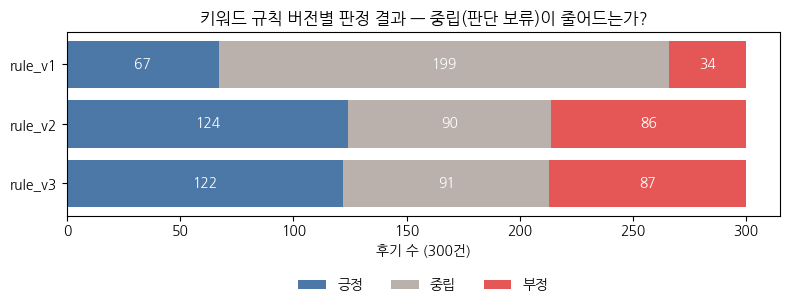

In [19]:
order = ["긍정", "중립", "부정"]; colors = {"긍정": "#4C78A8", "중립": "#BAB0AC", "부정": "#E45756"}
dist = pd.DataFrame({c: df[c].value_counts() for c in ["rule_v1", "rule_v2", "rule_v3"]}).reindex(order).fillna(0).T
fig, ax = plt.subplots(figsize=(8, 3.4))
left = np.zeros(len(dist))
for lab in order:
    ax.barh(dist.index, dist[lab], left=left, color=colors[lab], label=lab)
    for y, (l, v) in enumerate(zip(left, dist[lab])):
        if v >= 12: ax.text(l + v / 2, y, int(v), ha="center", va="center", color="white")
    left += dist[lab].values
ax.invert_yaxis(); ax.set_xlabel("후기 수 (300건)"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.28), frameon=False)
ax.set_title("키워드 규칙 버전별 판정 결과 — 중립(판단 보류)이 줄어드는가?")
plt.tight_layout(); plt.savefig("figures/fig_w2_rule_versions.png", dpi=120); plt.show()

**생각해 보기:** 단어를 계속 늘리면 판정 비율은 오르지만, 엉뚱한 단어가 걸려 **틀리는 경우도 늘어납니다**.
사람이 규칙을 만들 때의 장점(이유가 분명함)과 한계(끝없이 예외가 생김)를 정리하세요.

---
# 워크북 3 · AI(머신러닝) 감성분석
키워드 규칙은 **사람이** 단어와 점수를 정했습니다. 머신러닝은 **별점이 붙은 후기 19만 9천여 건**을 보고
어떤 글자 조각이 긍정·부정과 함께 나오는지 **가중치를 스스로 학습**합니다.

```
후기 문장 ──▶ ① 글자 조각(n-gram)으로 자르기 ──▶ ② TF-IDF 숫자 벡터 ──▶ ③ 로지스틱 회귀 ──▶ 긍정 확률 0~1
"배송 빠르고"     " 배", "배송", "송 ", " 빠", "빠르" …      [0, 0.21, 0, 0.13 …]      Σ(가중치 × 값)        0.5 이상 → 긍정
```
| 용어 | 뜻 |
|---|---|
| 학습 데이터 | 원자료 20만 건 중 **수업 300건을 뺀** 199,700건 (시험 문제를 미리 보지 않게 분리) |
| 문자 n-gram | 2~4글자씩 잘라낸 조각. 띄어쓰기·오타·조사 변화에 강함 |
| TF-IDF | 이 문장에 자주 나오고(TF) 다른 문장엔 드문(IDF) 조각일수록 큰 값 |
| 로지스틱 회귀 | 조각마다 가중치(+면 긍정 쪽, −면 부정 쪽)를 학습해 합을 확률로 바꿈 |

### 3-1. 학습 데이터 준비 — 수업 300건은 반드시 제외

In [20]:
gz = check_file("naver_shopping.txt.gz")
corpus = pd.read_csv(io.BytesIO(gzip.decompress(gz)), sep="\t", header=None,
                     names=["rating", "review_text"], quoting=3, dtype={"review_text": "string"})
corpus["src_line"] = range(1, len(corpus) + 1)

# TODO 8: 수업 300건(src_line이 같은 행)을 학습 데이터에서 빼세요.  힌트: ~corpus["src_line"].isin(df["src_line"])
train = corpus[~corpus["src_line"].isin(df["src_line"])].dropna(subset=["review_text"]).copy()
train["label"] = (train["rating"] >= 4).astype(int)            # 1 = 긍정(별점 4~5), 0 = 부정(1~2)
print("원자료:", len(corpus), "→ 학습용:", len(train), "| 긍정 비율:", round(train["label"].mean(), 3))
print("수업 300건과 겹치는 행:", train["src_line"].isin(df["src_line"]).sum())

naver_shopping.txt.gz         7,699,143 bytes  →  정상(MD5 일치)


원자료: 200000 → 학습용: 199700 | 긍정 비율: 0.5
수업 300건과 겹치는 행: 0


**기대값:** 학습용 199,700행 · 긍정 비율 0.5 · 겹치는 행 **0**

### 3-2. 문장이 글자 조각으로 바뀌는 모습 보기

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=5)
print(vec.build_analyzer()("배송 빠르고 좋아요")[:20], "...")

[' 배', '배송', '송 ', ' 배송', '배송 ', ' 배송 ', ' 빠', '빠르', '르고', '고 ', ' 빠르', '빠르고', '르고 ', ' 빠르고', '빠르고 ', ' 좋', '좋아', '아요', '요 ', ' 좋아'] ...


### 3-3. 학습하기 (Colab 약 30초~1분)

In [22]:
t0 = time.time()
# TODO 9: ① 학습 문장으로 vec을 맞추고 숫자로 바꾼 뒤(fit_transform) ② 로지스틱 회귀를 학습(fit)하세요.
X_train = vec.fit_transform(train["review_text"])
model = LogisticRegression(max_iter=1000)
model.fit(X_train, train["label"])
print(f"학습 완료 {time.time() - t0:.0f}초 | 문장 {X_train.shape[0]:,}개 × 글자조각 {X_train.shape[1]:,}종")

학습 완료 20초 | 문장 199,700개 × 글자조각 226,445종


### 3-4. 수업 300건 예측

In [23]:
# TODO 10: 수업 300건의 긍정 확률을 구하세요.  힌트: model.predict_proba(vec.transform(df["text"]))[:, 1]
df["ai_prob"] = model.predict_proba(vec.transform(df["text"]))[:, 1].round(3)
df["ai_label"] = np.where(df["ai_prob"] >= 0.5, "긍정", "부정")
print(df["ai_label"].value_counts().to_dict())
df[["review_id", "rating_label", "rule_v2", "ai_label", "ai_prob", "text"]].head(10)

{'부정': 158, '긍정': 142}


,review_id,rating_label,rule_v2,ai_label,ai_prob,text
0,R001,긍정,긍정,긍정,0.970,오리상태도 좋고 밋도 있어여 다만 포장에 기름이 좀 묻어 있어서 별하나 뺐어요
1,R002,긍정,중립,긍정,0.855,세팅력이 우수합니다
2,R003,긍정,긍정,긍정,0.743,"화장하기 편하고, 피부표현이 매끄럽게 되용"
3,R004,부정,부정,부정,0.010,뚜껑끼우는게 너무 힘들어서 손이 많이 아픕니다. 통이 찌그러져오지않았다면 그렇게 힘들진않을텐데 10개중 서너개는 심하게 찌그러져오네요. ...
4,R005,부정,부정,부정,0.134,일단 패드장착이 안되어 왔구요~ 패드부분만 볼록하게 튀어나와서 너무 티가나요~
5,R006,긍정,긍정,긍정,0.843,일단 강추 입니다 세련 되었고 싼티 나지 않습니다 만족스럽스니다
6,R007,긍정,중립,긍정,0.833,잘받았어요. 잘쓸깨요
7,R008,긍정,긍정,긍정,0.744,대구지역~~아직 제품과 만나지 못했네요 친절하게도 집안에 배송을 해주셔서~~
8,R009,부정,긍정,긍정,0.981,사료 두번째 구입인데 넘잘먹네요 계량컵두 주시고 배송도빠르고 적극 추천합니다
9,R010,긍정,긍정,긍정,0.759,맛있었어요 2명 먹는데 양도적당했는데 당면양이 아주많네요


### 3-5. AI가 중요하게 본 단서 — 사람이 고른 키워드와 비교

,긍정 쪽 조각,가중치(+),부정 쪽 조각,가중치(−)
0,좋,10.26,안,-8.42
1,잘,7.35,별로,-7.09
2,!,7.21,별,-6.85
3,좋아,6.62,실망,-6.43
4,만족,6.32,못,-6.39
5,맛있,6.14,불,-5.94
6,편,5.93,ㅠ,-5.64
7,최고,5.65,비추,-5.29
8,굿,4.88,최악,-5.14
9,좋아요.,4.70,별로,-5.02


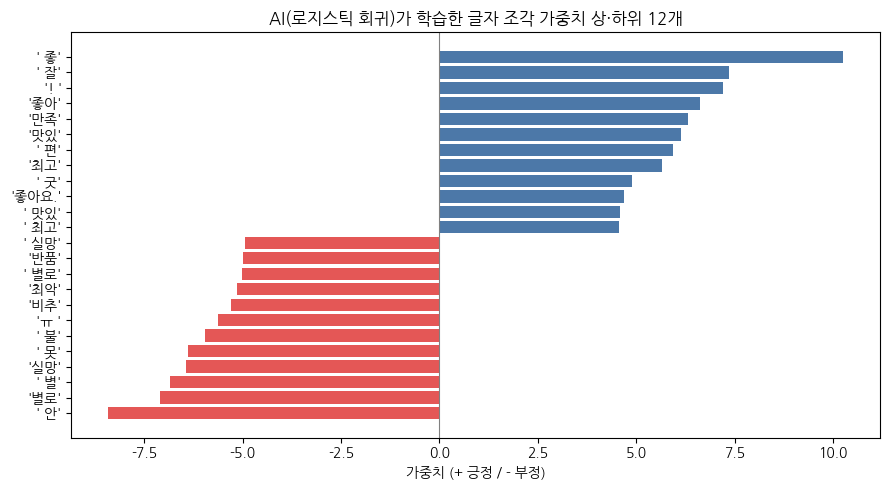

In [24]:
names = np.array(vec.get_feature_names_out()); coef = model.coef_[0]
order_ = np.argsort(coef)
cues = pd.DataFrame({"긍정 쪽 조각": names[order_[::-1][:15]], "가중치(+)": coef[order_[::-1][:15]].round(2),
                     "부정 쪽 조각": names[order_[:15]], "가중치(−)": coef[order_[:15]].round(2)})
display(cues)

fig, ax = plt.subplots(figsize=(9, 5))
idx = np.r_[order_[:12], order_[-12:]]
ax.barh([repr(n) for n in names[idx]], coef[idx], color=["#E45756"] * 12 + ["#4C78A8"] * 12)
ax.axvline(0, color="gray", lw=.8); ax.set_xlabel("가중치 (+ 긍정 / - 부정)")
ax.set_title("AI(로지스틱 회귀)가 학습한 글자 조각 가중치 상·하위 12개")
plt.tight_layout(); plt.savefig("figures/fig_w3_ai_cues.png", dpi=120); plt.show()

**관찰:** `좋아`, `만족`, `최고`, `별로`, `실망`, `반품`처럼 **사람이 고른 단어를 AI도 찾았습니다.**
그런데 사람이 생각하지 못한 `' 안'`(부정어), `'ㅠ '`, `'..'`, `'그냥'`, `'! '`, `'^ '` 같은 **말투·기호**도 단서로 씁니다.

### 3-6. 한 문장을 AI는 어떻게 판단했나?

In [25]:
def explain(review_id, k=5):
    t = df.loc[df["review_id"] == review_id, "text"].iloc[0]
    x = vec.transform([t]); contrib = x.multiply(coef).tocsr()
    cols, vals = contrib.indices, contrib.data
    o = np.argsort(vals)
    print(f"[{review_id}] {t}")
    print("  긍정 확률:", round(float(model.predict_proba(x)[0, 1]), 3))
    print("  ➕ 긍정 쪽:", [(names[cols[i]], round(float(vals[i]), 2)) for i in o[::-1][:k] if vals[i] > 0])
    print("  ➖ 부정 쪽:", [(names[cols[i]], round(float(vals[i]), 2)) for i in o[:k] if vals[i] < 0])

for rid in ["R009", "R111", "R295"]:
    explain(rid); print()

[R009] 사료 두번째 구입인데 넘잘먹네요 계량컵두 주시고 배송도빠르고 적극 추천합니다
  긍정 확률: 0.981
  ➕ 긍정 쪽: [('잘먹', 0.26), ('빠르', 0.25), ('주시고', 0.21), ('주시고 ', 0.18), ('째 ', 0.17)]
  ➖ 부정 쪽: [('두번', -0.1), ('네요 ', -0.09), (' 배송', -0.07), (' 두번', -0.07), ('네요', -0.05)]

[R111] 면부분이 좁고 허벅지 쪽이 말려 올라갑니다 그밖의 것은 만족
  긍정 확률: 0.125
  ➕ 긍정 쪽: [('만족', 0.41), (' 만족', 0.26), ('만족 ', 0.15), ('족 ', 0.14), (' 만', 0.12)]
  ➖ 부정 쪽: [('이 ', -0.3), (' 그', -0.21), (' 허', -0.2), ('부분', -0.17), ('려 ', -0.13)]

[R295] 접착성 완전 안좋아요ㅜ 다시샀네요 다른걸로
  긍정 확률: 0.023
  ➕ 긍정 쪽: [('좋아', 0.38), ('좋아요', 0.24), (' 완', 0.15), ('샀네요', 0.06), ('샀네', 0.05)]
  ➖ 부정 쪽: [(' 안', -0.5), ('안좋', -0.46), ('안좋아요', -0.38), (' 안좋', -0.31), ('ㅜ ', -0.29)]



**생각해 보기:** R111 *"면부분이 좁고 허벅지 쪽이 말려 올라갑니다 그밖의 것은 만족"* 은 별점 5점인데 AI는 부정(0.125)으로 봅니다. 누가 맞을까요?
R295 *"접착성 완전 안좋아요"* 에서는 `좋`이 긍정 쪽으로 당겨도 `안`·`ㅠ` 같은 조각이 더 크게 부정 쪽으로 당겨 부정이 됩니다.
AI도 결국 **조각의 가중치를 더하는 계산**이라 문장의 무게중심(무엇이 더 중요한가)은 모릅니다.

### 3-7. AI는 얼마나 확신하나?

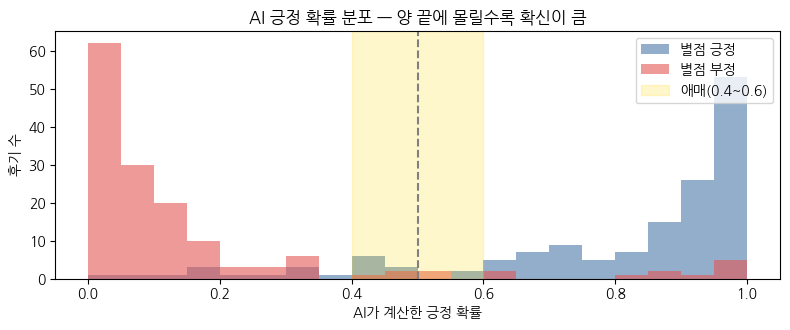

애매한 후기(0.4~0.6): 16 건


,review_id,rating_label,ai_prob,text
73,R074,긍정,0.557,계속써봐야 알것같습니다 아직은 잘모르겟네요.. 고무가 탄탄한것은 마음에듭니다 효과가있을지 믿고써봐야겟죠
100,R101,부정,0.472,초당초당해서 사먹어봤는ㄷㅔ 찰옥수수가더 맛난것같습니다. 제취향은아닙니다
109,R110,긍정,0.573,일단 사이즈는 작습니다 좀더 먹어보고 후기 올리겠습니다.
136,R137,긍정,0.412,필드나갈때볼에도장찍어가져갔는데 너무깔끔하고안지워짐..굿샷
139,R140,긍정,0.485,생각보다는 얇은감이 있네요
143,R144,긍정,0.405,빠른 배송과 사진과 같은 상품
168,R169,긍정,0.419,재질이 단단해서 오래사용할수 있을것같아요 똑딱이 부분은 약해서 바로 떨어졌는데 없이사욘해도 지장은 없을것 같아요
169,R170,부정,0.540,열심히 지울려고 하였지만 잘지워지지않아 크게 만족하지 못한 상태에서 바로 교통사고가나 폐차하여 지속력은 잘 몰르겠네요 ㅎ..망할


In [26]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for lab, col in [("긍정", "#4C78A8"), ("부정", "#E45756")]:
    ax.hist(df.loc[df["rating_label"] == lab, "ai_prob"], bins=np.linspace(0, 1, 21), alpha=.6, color=col, label=f"별점 {lab}")
ax.axvspan(0.4, 0.6, color="gold", alpha=.2, label="애매(0.4~0.6)")
ax.axvline(0.5, color="gray", ls="--"); ax.set_xlabel("AI가 계산한 긍정 확률"); ax.set_ylabel("후기 수"); ax.legend()
ax.set_title("AI 긍정 확률 분포 — 양 끝에 몰릴수록 확신이 큼")
plt.tight_layout(); plt.savefig("figures/fig_w3_ai_prob.png", dpi=120); plt.show()
unsure = df[df["ai_prob"].between(0.4, 0.6)]
print("애매한 후기(0.4~0.6):", len(unsure), "건")
display(unsure[["review_id", "rating_label", "ai_prob", "text"]].head(8))

> ⚠ **확률 0.98 ≠ 98% 정확.** 확률은 모델이 학습한 패턴에 얼마나 잘 들어맞는지일 뿐입니다.
> 별점 2점인 R009를 0.98로 '긍정'이라 확신하는 것처럼, 높은 확률로 '별점과 다른' 답을 낼 수 있습니다.

### 3-8. (심화·선택) 사전학습 언어모델로 해 보기
Hugging Face의 한국어 감성 모델을 내려받아 같은 300건을 분류할 수 있습니다. 모델 파일(약 450MB)을 받아야 해서
**수업 기본 실습에서는 끄고(`RUN_PRETRAINED = False`)**, 시간이 남거나 과제로 해 볼 때 `True`로 바꿉니다.
- 모델: `Copycats/koelectra-base-v3-generalized-sentiment-analysis` (출력 `0`=부정, `1`=긍정, Apache-2.0)
- 주의: 모델 카드에 학습 데이터가 명시되어 있지 않아 **수업 데이터와 같은 원자료로 학습되었을 가능성**을 배제할 수 없습니다(그러면 점수가 부풀려짐). 결과는 비교 참고용으로만 씁니다.
- 이 셀은 강의자료 제작 환경에서 실행 검증하지 못했습니다(Colab에서 실행). 실패하면 오류 화면을 기록하고 **결과를 지어내지 않습니다.**

In [27]:
RUN_PRETRAINED = False

if RUN_PRETRAINED:
    !pip -q install transformers
    from transformers import pipeline
    clf = pipeline("text-classification", model="Copycats/koelectra-base-v3-generalized-sentiment-analysis")
    print("모델 라벨:", clf.model.config.id2label)
    out = clf(df["text"].tolist(), batch_size=16, truncation=True, max_length=128)
    to_kr = {"0": "부정", "1": "긍정", "LABEL_0": "부정", "LABEL_1": "긍정", "negative": "부정", "positive": "긍정"}
    df["llm_label"] = [to_kr[str(o["label"])] for o in out]
    print("사전학습 모델 vs 별점 일치:", round((df["llm_label"] == df["rating_label"]).mean(), 3))
    print("사전학습 모델 vs 우리 AI 일치:", round((df["llm_label"] == df["ai_label"]).mean(), 3))
else:
    print("심화 실습을 건너뜁니다. (RUN_PRETRAINED = True 로 바꾸면 실행)")

심화 실습을 건너뜁니다. (RUN_PRETRAINED = True 로 바꾸면 실행)


---
# 워크북 4 · 수작업 규칙 vs AI 비교 · 평가
```
① 두 방법끼리 비교(교차표·일치율) → ② 각각 별점 라벨과 비교(정확도·재현율) → ③ 불일치·잡음 사례를 사람이 읽고 최종 판단 → ④ 개선안
```
| 지표 | 뜻 | 주의 |
|---|---|---|
| 일치율 | 두 방법이 같은 답을 낸 비율 | 둘 다 틀려도 '일치' |
| 정확도(accuracy) | 별점 라벨과 같은 비율 | 별점 라벨에도 잡음이 있음 |
| 정밀도(precision) | '부정'이라 한 것 중 진짜 부정 비율 | 오탐(괜히 부정) 확인 |
| 재현율(recall) | 진짜 부정 중 '부정'이라 찾아낸 비율 | 놓친 불만 확인 |

### 4-1. 규칙 v2와 AI 비교

In [28]:
# TODO 11: 규칙 v2(행)와 AI(열)의 교차표를 만드세요.  힌트: pd.crosstab(df["rule_v2"], df["ai_label"], margins=True)
ct = pd.crosstab(df["rule_v2"], df["ai_label"], margins=True, margins_name="합계")
display(ct)
both = df[df["rule_v2"] != "중립"]
print("규칙이 판정한", len(both), "건 중 AI와 일치:", round((both["rule_v2"] == both["ai_label"]).mean(), 3))

ai_label,긍정,부정,합계
rule_v2,,,
긍정,107,17,124
부정,4,82,86
중립,31,59,90
합계,142,158,300


규칙이 판정한 210 건 중 AI와 일치: 0.9


### 4-2. 별점 라벨 기준 성적표

In [29]:
from sklearn.metrics import classification_report, confusion_matrix

summary = pd.DataFrame({
    "규칙 v1": rule_score("rule_v1"), "규칙 v2": rule_score("rule_v2"), "규칙 v3(나)": rule_score("rule_v3"),
    "AI": pd.Series({"판정 비율(중립 제외)": 1.0,
                      "판정한 것 중 별점 일치": (df["ai_label"] == df["rating_label"]).mean(),
                      "전체 300건 기준 일치": (df["ai_label"] == df["rating_label"]).mean()}).round(3)})
display(summary)
print("AI 상세 (별점 라벨 기준)")
print(classification_report(df["rating_label"], df["ai_label"], digits=3))

,규칙 v1,규칙 v2,규칙 v3(나),AI
판정 비율(중립 제외),0.337,0.700,0.697,1.000
판정한 것 중 별점 일치,0.842,0.881,0.885,0.887
전체 300건 기준 일치,0.283,0.617,0.617,0.887


AI 상세 (별점 라벨 기준)
              precision    recall  f1-score   support

          긍정      0.908     0.860     0.884       150
          부정      0.867     0.913     0.890       150

    accuracy                          0.887       300
   macro avg      0.888     0.887     0.887       300
weighted avg      0.888     0.887     0.887       300



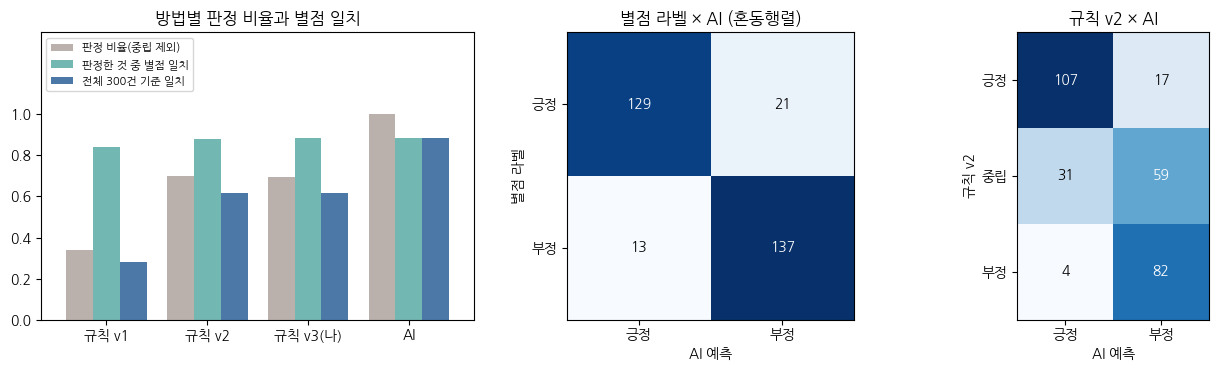

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
m = summary.loc[["판정 비율(중립 제외)", "판정한 것 중 별점 일치", "전체 300건 기준 일치"]].T
m.plot.bar(ax=axes[0], color=["#BAB0AC", "#72B7B2", "#4C78A8"], rot=0, width=.8)
axes[0].set_ylim(0, 1.4); axes[0].set_yticks([0, .2, .4, .6, .8, 1.0]); axes[0].set_title("방법별 판정 비율과 별점 일치"); axes[0].legend(fontsize=8, loc="upper left", ncol=1)

def heat(ax, table, title):
    ax.imshow(table.values, cmap="Blues")
    ax.set_xticks(range(table.shape[1]), table.columns); ax.set_yticks(range(table.shape[0]), table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            ax.text(j, i, v, ha="center", va="center", color="white" if v > table.values.max() / 2 else "black")
    ax.set_title(title)

heat(axes[1], pd.crosstab(df["rating_label"], df["ai_label"]).rename_axis(index="별점", columns="AI"), "별점 라벨 × AI (혼동행렬)")
axes[1].set_xlabel("AI 예측"); axes[1].set_ylabel("별점 라벨")
heat(axes[2], pd.crosstab(df["rule_v2"], df["ai_label"]).reindex(["긍정", "중립", "부정"]), "규칙 v2 × AI")
axes[2].set_xlabel("AI 예측"); axes[2].set_ylabel("규칙 v2")
plt.tight_layout(); plt.savefig("figures/fig_w4_compare.png", dpi=120); plt.show()

**기대값:** AI 정확도 **0.887** (긍정 재현율 0.860 · 부정 재현율 0.913) · 규칙 v2는 판정한 210건만 보면 0.881로 AI와 비슷하지만 **300건 전체 기준 0.617**.
규칙 v2와 AI는 규칙이 판정한 210건 중 **0.90** 일치, 정반대 21건 · 별점 잡음 후보 8건 · AI 애매(0.4~0.6) 16건.

### 4-3. 불일치·잡음 사례 — 사람이 최종 판단

In [31]:
dis = df[(df["rule_v2"] != "중립") & (df["rule_v2"] != df["ai_label"])]
print("① 규칙과 AI가 정반대로 판단:", len(dis), "건")
display(dis[["review_id", "rating", "rule_v2", "ai_label", "ai_prob", "text"]].head(10))

noise = df[((df["ai_prob"] >= 0.9) & (df["rating"] <= 2)) | ((df["ai_prob"] <= 0.1) & (df["rating"] >= 4))]
print("② AI가 강하게 확신하는데 별점과 반대 (별점 잡음 후보):", len(noise), "건")
display(noise[["review_id", "rating", "rule_v2", "ai_label", "ai_prob", "text"]])

① 규칙과 AI가 정반대로 판단: 21 건


,review_id,rating,rule_v2,ai_label,ai_prob,text
55,R056,4,긍정,부정,0.244,"편하게넣었다뺏다하는건저알좋습니다 다만, 3m부착면이너무좁아시간이지나면잘떨어질것같습니다 또한케이스있는것은잘안됩니다 그리고깊게넣으면스마트폰화..."
79,R080,2,긍정,부정,0.028,가격이 저렴하니까 어느정도 예상은 했지만 단추를 다 여미고 나니까 끝선 기장이 서로 맞지않네요..마감처리가 너무 엉성해서 입고 다니기 부...
86,R087,2,긍정,부정,0.053,음..다른 밀크클렌져 쓰다가 이제품은.첫사용인데..이제품 괜찮은거 맞나요??..엄청 미끄덩거리고..지금..눈도 엄청 흐리고 끔뻑 끔뻑 거...
95,R096,2,긍정,부정,0.069,상품평이 좋아서 샀는데 불편해요 앞에도 짧고 한치수 크게 주문하세요
105,R106,2,긍정,부정,0.071,물광도 나지 않고 그냥 에센스 느낌이 강하다. 아직까지 좋은점은 발견 하지 못했다 그냥 미스트 같다
110,R111,5,긍정,부정,0.125,면부분이 좁고 허벅지 쪽이 말려 올라갑니다 그밖의 것은 만족
136,R137,5,긍정,부정,0.412,필드나갈때볼에도장찍어가져갔는데 너무깔끔하고안지워짐..굿샷
138,R139,4,긍정,부정,0.330,간단히 사용하기에는 그럭저럭 괜찮은것 같습니다
140,R141,4,긍정,부정,0.332,전체적으로 대가 약해보임 가격에 비해 수납공간은 괜찮았습니다
150,R151,4,부정,긍정,0.630,롱으로 사고싶었는데 키가작아 선택했어요 색상 길이 화면과같아요 핑크선택했는데 촌스럽지않은 색상이랍니다 키가작아도 롱으로 도전해보려고요


② AI가 강하게 확신하는데 별점과 반대 (별점 잡음 후보): 8 건


,review_id,rating,rule_v2,ai_label,ai_prob,text
8,R009,2,긍정,긍정,0.981,사료 두번째 구입인데 넘잘먹네요 계량컵두 주시고 배송도빠르고 적극 추천합니다
58,R059,4,부정,부정,0.043,배송이 너어어무 느림
62,R063,2,중립,긍정,0.951,자주 쓰던거에요 잘쓸께요
67,R068,1,긍정,긍정,0.986,배송도 빠르고 포장도 잘 되어왔어요. 잘 사용할게요
81,R082,2,긍정,긍정,0.965,조금 비싼거 같아요 그래도 맛있어요
84,R085,1,긍정,긍정,0.981,배송도빠르고 원하던디자인에 차량색상이랑도 잘맞고 딱이네요
128,R129,2,긍정,긍정,0.900,괜찮은것같아요~~
153,R154,4,부정,부정,0.076,두껍고 냄새없어요. 끈이 바깥쪽인데 옆면이 펀칭마감이라 뜨네요.


**과제:** ①에서 3건, ②에서 2건을 골라 **내 최종 판단(긍정/부정/중립)과 근거**를 워크북 기록지에 적으세요.
②의 상당수는 *문장은 칭찬인데 별점이 낮은* 후기입니다 → "AI가 틀렸다"가 아니라 **라벨이 틀렸을 수 있다**는 것도 데이터 분석의 발견입니다.

### 4-4. 결과 저장

In [32]:
cols = ["review_id", "src_line", "rating", "rating_label", "review_text", "text", "length",
        "rule_v1", "rule_v2", "rule_v3", "ai_label", "ai_prob"]
df[cols].to_csv("week06_results.csv", index=False, encoding="utf-8-sig")
dis[cols].to_csv("week06_disagreements.csv", index=False, encoding="utf-8-sig")
summary.to_csv("week06_method_summary.csv", encoding="utf-8-sig")
print("저장: week06_results.csv, week06_disagreements.csv, week06_method_summary.csv, figures/*.png")

# 기준 결과 (완성본 실행값과 비교)
basis = {
    "규칙v1 판정/일치(판정분)/일치(전체)": tuple(rule_score("rule_v1")),
    "규칙v2 판정/일치(판정분)/일치(전체)": tuple(rule_score("rule_v2")),
    "AI 정확도": round((df["ai_label"] == df["rating_label"]).mean(), 3),
    "규칙v2-AI 일치(규칙 판정분)": round((both["rule_v2"] == both["ai_label"]).mean(), 3),
    "규칙v2-AI 정반대": len(dis), "별점 잡음 후보": len(noise),
    "애매(0.4~0.6)": len(unsure),
}
for k, v in basis.items():
    print(f"{k:32s} {v}")

저장: week06_results.csv, week06_disagreements.csv, week06_method_summary.csv, figures/*.png
규칙v1 판정/일치(판정분)/일치(전체)           (0.337, 0.842, 0.283)
규칙v2 판정/일치(판정분)/일치(전체)           (0.7, 0.881, 0.617)
AI 정확도                           0.887
규칙v2-AI 일치(규칙 판정분)               0.9
규칙v2-AI 정반대                      21
별점 잡음 후보                         8
애매(0.4~0.6)                      16


### 기준 결과 (완성본 실행값 · 실습본 결과와 비교)
| 방법 | 판정 비율 | 판정한 것 중 별점 일치 | 300건 전체 기준 일치 |
|---|---|---|---|
| 규칙 v1 (단어 8+8개) | 0.337 | 0.842 | 0.283 |
| 규칙 v2 (단어 확장 + 부정어) | 0.700 | 0.881 | 0.617 |
| AI (TF-IDF + 로지스틱 회귀) | 1.000 | 0.887 | **0.887** |

규칙 v2 vs AI: 규칙이 판정한 210건 중 일치 0.90 · 정반대 21건 · 별점 잡음 후보 8건 · AI 애매(0.4~0.6) 16건.
학습 문장 199,700개 × 글자조각 226,445종. (scikit-learn 버전에 따라 AI 값이 ±0.01 정도 다를 수 있음)

### 토의 · 제출
1. **규칙과 AI의 장단점**을 표로 정리하세요 (설명 가능성, 판정 범위, 새로운 표현, 만드는 데 드는 노력, 틀렸을 때 고치기).
2. 별점 라벨로 잰 정확도를 그대로 믿으면 안 되는 이유 2가지.
3. **고객 서비스 개선 제안(150자 이상):** 부정 후기에서 자주 나온 원인(배송·사이즈·불량·냄새 …)을 근거로 쇼핑몰이 할 일을 제안하세요.
   AI 결과는 **우선 검토 대상을 고르는 도구**로 쓰고, 최종 판단은 사람이 한다는 점을 포함합니다.

**제출물:** `week06_results.csv` · `week06_disagreements.csv` · `figures/` 그림 · 워크북 기록지(Sheets) · 토의 답안